<h1><font color="#113D68" size=6>
TINTOlib: de datos tabulares a imágenes sintéticas
</font></h1>

<h1><font color="#113D68" size=5>
Mejorar el aprendizaje profundo sobre datos tabulares mediante imágenes sintéticas
</font></h1>

<h1><font color="#113D68" size=4>
Notebook 01 · Regresión con CNN (PyTorch)
</font></h1>

<br><br>

<div style="text-align: right">
<font color="#113D68" size=3>Manuel Castillo-Cara</font><br>
</div>


---
<a id="indice" name="indice"></a>
<h2><font color="#004D7F" size=5>Índice</font></h2>

- [0. Contexto](#section0)
- [1. Configuración](#section1)
- [2. Dataset y particiones](#section2)
- [3. Transformaciones con TINTOlib](#section3)
- [4. Imágenes generadas](#section4)
- [5. Arquitectura CNN](#section5)
- [6. Entrenamiento y resultados](#section6)
- [7. Explicabilidad visual (opcional)](#section7)
- [8. Conclusiones](#section8)
- [9. Ejercicios](#section9)
- [10. Referencias](#section10)


<div class="alert alert-block alert-info">
    
<i class="fa fa-info-circle" aria-hidden="true"></i>
More information about [Manuel Castillo-Cara](https://www.manuelcastillo.eu/)

<div class="alert alert-block alert-info">

<i class="fa fa-info-circle" aria-hidden="true"></i>
Puedes ver más cursos de Inteligencia Artificial, Machine Learning y Deep Learning con descuento en mi [Página Web Personal](https://www.manuelcastillo.eu/udemy/)

<a id="section0" name="section0"></a>
# <font color="#004D7F" size=6>0. Contexto</font>
6. **Resultado concreto de la ejecución:** aquí la CNN con TINTO 4×4 y `blur=True` apenas supera una referencia simple (`R² ≈ -0.01`). Esto ayuda a transmitir que la representación tabular-a-imagen debe evaluarse empíricamente.


Los datos tabulares contienen variables numéricas o categóricas, pero no poseen necesariamente una vecindad espacial. **TINTOlib** transforma las observaciones en imágenes para poder utilizar arquitecturas de visión. Distintos métodos producen representaciones diferentes de las mismas variables.

Este ejemplo parte de **Diabetes**, utiliza **TINTO** y estudia una red **CNN**. Primero examinaremos la transformación y sus imágenes; después observaremos cómo las procesa PyTorch. **Una imagen sintética representa una observación de la tabla; no crea un paciente o registro nuevo.**


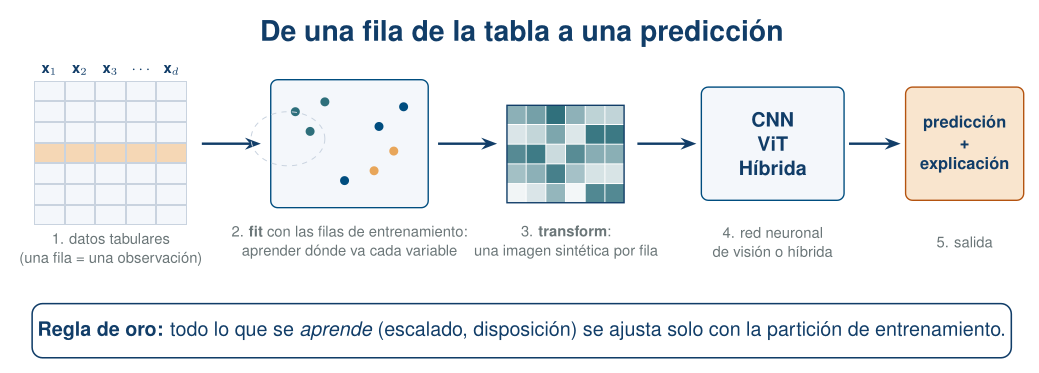

<p style="text-align:center; color:#555555;"><em><strong>Figura 1.</strong> Del registro tabular a la imagen sintética y a la predicción. La disposición se aprende únicamente con TRAIN; el diagrama muestra el proceso general de TINTOlib.</em></p>


<div class="alert alert-info" style="background-color:#eaf6fb; border-left:4px solid #00838A; padding:12px 15px; border-radius:5px; margin:12px 0;">
<strong>Objetivos de aprendizaje</strong><br>
Identificar qué información recibe <strong>TINTO</strong>, interpretar el tamaño y la disposición de las imágenes, comprender el flujo general de <strong>CNN</strong> en PyTorch y leer sus métricas. La explicabilidad se presenta como una actividad visual opcional.
</div>


<div class="alert alert-warning" style="background-color:#fff6e3; border-left:4px solid #cc8a25; padding:12px 15px; border-radius:5px; margin:12px 0;">
<strong>Alcance del taller</strong><br>
Se ejecuta una demostración de pocas épocas y una única partición TRAIN/VALIDATION. No es una comparación científica concluyente entre transformadores ni arquitecturas. El conjunto TEST de cualquier desafío posterior permanece separado.
</div>


---
<div style="text-align: right">
<font size=5>
<a href="#indice">Volver al índice</a>
</font>
</div>


<a id="section1" name="section1"></a>
# <font color="#004D7F" size=6>1. Configuración</font>


La primera celda prepara TINTOlib para el entorno de práctica. La siguiente importa las librerías y muestra las opciones que el estudiante puede modificar: `DATASET`, `METODO`, `EPOCAS` y, en el ViT, `PATCH`.

No hace falta entender cada importación: **PyTorch** define la red y entrena sus parámetros; **TINTOlib** genera las imágenes; **scikit-learn** facilita el dataset, las particiones y las métricas.


In [ ]:
# Si estás en Google Colab, ejecuta esta celda una sola vez.
# Utilizamos 1.3.2: la release 1.3.3 está pendiente de correcciones.
%pip -q install "TINTOlib==1.3.2"


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
import math
from pathlib import Path
from importlib import import_module
from uuid import uuid4
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, accuracy_score, f1_score
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import TensorDataset, DataLoader

SEMILLA = 42
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)
DISPOSITIVO = torch.device("cuda" if torch.cuda.is_available() else
                          "mps" if hasattr(torch.backends, "mps") and torch.backends.mps.is_available()
                          else "cpu")
print("PyTorch:", torch.__version__, "| Dispositivo:", DISPOSITIVO)

# CAMBIA SOLO ESTAS OPCIONES PARA REALIZAR LOS EJERCICIOS
DATASET = "diabetes"
ARCHIVO_CSV = ""  # Opcional: ruta del CSV propio, con objetivo en última columna
METODO = "TINTO"
EPOCAS = 5            # Demostración breve; no es una búsqueda de hiperparámetros
PATCH = 2             # Solo importa para ViT: se explica más adelante

PyTorch: 2.9.1 | Dispositivo: mps


<div class="alert alert-info" style="background-color:#eaf6fb; border-left:4px solid #00838A; padding:12px 15px; border-radius:5px; margin:12px 0;">
<strong>Cómo interpretar esta salida</strong><br>
Se muestra la versión de PyTorch y el dispositivo elegido (<code>cpu</code>, <code>cuda</code> o <code>mps</code>). Es información de ejecución, <b>no un resultado del modelo</b>. Se utiliza TINTOlib 1.3.2 en estos materiales; la 1.3.3 no es una versión de referencia aprobada.
</div>


---
<div style="text-align: right">
<font size=5>
<a href="#indice">Volver al índice</a>
</font>
</div>


<a id="section2" name="section2"></a>
# <font color="#004D7F" size=6>2. Dataset y particiones</font>


**Diabetes** tiene 10 variables numéricas y un objetivo continuo relacionado con la progresión de la enfermedad. La tarea es **regresión**. La escala del objetivo se aprende en TRAIN para facilitar el entrenamiento y después se invierte para calcular las métricas en sus unidades originales.

Primero dividimos las filas en **TRAIN (80 %)** y **VALIDATION (20 %)**. Imputación, codificación, escalado y parámetros aprendidos se ajustan exclusivamente con TRAIN; al generar imágenes de VALIDATION se reutiliza el transformador ya ajustado.


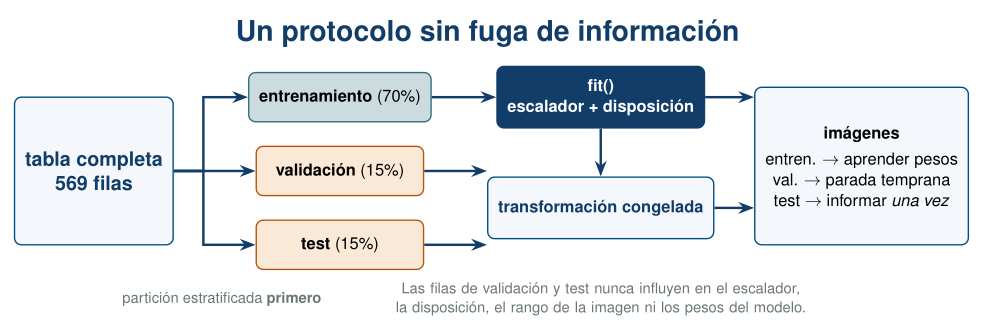

<p style="text-align:center; color:#555555;"><em><strong>Figura 2.</strong> Protocolo de separación de datos. Aunque el diagrama incluya TEST para ilustrar una evaluación completa, este notebook trabaja solo con TRAIN y VALIDATION.</em></p>


Elegimos el tipo de dataset a trabajar

In [4]:
from sklearn.datasets import load_diabetes, load_breast_cancer, load_wine, make_regression

if ARCHIVO_CSV:
    tabla = pd.read_csv(ARCHIVO_CSV)
    id_datos = Path(ARCHIVO_CSV).stem
elif DATASET == "diabetes":
    tabla = load_diabetes(as_frame=True).frame.copy()
    id_datos = "Diabetes"
elif DATASET == "cancer":
    tabla = load_breast_cancer(as_frame=True).frame.copy()
    id_datos = "Breast Cancer Wisconsin"
elif DATASET == "wine":
    tabla = load_wine(as_frame=True).frame.copy()
    id_datos = "Wine"
elif DATASET in ("regresion_8", "regresion_12"):
    n = int(DATASET.split("_")[-1])
    X, y = make_regression(n_samples=360, n_features=n, n_informative=max(4, n // 2),
                           noise=20, random_state=SEMILLA)
    tabla = pd.DataFrame(X, columns=[f"x{j+1}" for j in range(n)])
    tabla["target"] = y
    id_datos = f"Regresión sintética ({n} variables)"
else:
    raise ValueError(f"Dataset no reconocido: {DATASET}")

Eligimos el tipo de problema que sería según el problema: Regresión o clasificación

In [5]:
TAREA = "regression"  # regression o classification
objetivo = tabla.columns[-1]
print(id_datos, "| Observaciones:", len(tabla), "| Variables:", len(tabla.columns)-1)
display(tabla.head(3))

Diabetes | Observaciones: 442 | Variables: 10


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0


**Partición de datos, alineación de variables e imputación**

Se divide el dataset en **TRAIN (80 %)** y **VALIDATION (20 %)**. Se codifican las variables categóricas mediante *One-Hot Encoding* forzando a que validación mantenga exactamente la misma estructura de columnas que entrenamiento (`.reindex`). Finalmente, se limpian posibles infinitos y se imputan los valores ausentes (`NaN`) utilizando **exclusivamente la mediana calculada en `TRAIN`** para evitar fuga de información (*data leakage*).


In [7]:
tr, va = train_test_split(tabla, test_size=0.20, random_state=SEMILLA,
                          stratify=tabla[objetivo] if TAREA == "classification" else None)
tr, va = tr.reset_index(drop=True), va.reset_index(drop=True)
X_tr = pd.get_dummies(tr.drop(columns=objetivo), dummy_na=True, dtype=float)
X_va = pd.get_dummies(va.drop(columns=objetivo), dummy_na=True, dtype=float).reindex(
    columns=X_tr.columns, fill_value=0)
X_tr, X_va = X_tr.replace([np.inf, -np.inf], np.nan), X_va.replace([np.inf, -np.inf], np.nan)
medianas = X_tr.median().fillna(0)  # Exclusivamente TRAIN
X_tr, X_va = X_tr.fillna(medianas), X_va.fillna(medianas)

**Tratamiento de la variable objetivo ($y$)**
Según el tipo de problema definido en `TAREA`, se adapta la salida:
* **Clasificación:** `LabelEncoder` transforma las clases en índices enteros ($0, \dots, C-1$) y `num_salidas` toma el total de clases.
* **Regresión:** `StandardScaler` normaliza el objetivo usando solo los estadísticos de `TRAIN`. El escalador se guarda en `escala_y` para deshacer la transformación al final y expresar el error en las unidades reales del problema.


In [8]:
if TAREA == "classification":
    cod_y = LabelEncoder().fit(tr[objetivo])
    y_tr, y_va = cod_y.transform(tr[objetivo]), cod_y.transform(va[objetivo])
    num_salidas, escala_y = len(cod_y.classes_), None
else:
    escala_y = StandardScaler().fit(tr[[objetivo]])  # Solo TRAIN
    y_tr = escala_y.transform(tr[[objetivo]]).ravel()
    y_va = escala_y.transform(va[[objetivo]]).ravel()
    num_salidas = 1

In [11]:
print(y_va)

[ 0.8372342  -1.07421676  0.61914919  0.97834803 -0.54824703 -0.89461734
  1.13229039  1.51714629 -0.76633204 -0.74067498 -0.76633204  1.26057569
 -0.70218939  1.83785954 -0.24036232 -1.11270235  1.81220248  1.41451805
  0.20863623  1.55563188  2.00463043 -1.15118794 -0.33016203  1.00400509
 -0.3173335  -0.45844732  1.40168952 -0.98441705 -1.35644442 -0.59956115
 -0.17621967 -0.52258997 -0.81764616  0.13166505  0.33692153  1.01683362
 -1.4334156  -0.89461734  0.23429329 -1.16401647 -1.35644442 -0.58673262
  0.02903681  0.18297917 -0.81764616 -1.3051303   0.59349213 -0.85613175
 -0.81764616  1.33754687 -0.22753379  0.05469387 -1.08704529 -1.0485597
  0.22146476 -0.75350351 -1.0485597  -0.03510584  0.18297917 -1.20250206
 -0.40713321 -1.3051303   0.42672124 -0.6637038   0.77309155  1.20926157
  0.34975006 -0.56107556 -0.17621967  0.61914919 -0.67653233  0.87571979
  1.63260306 -1.18967353 -0.83047469 -0.80481763  0.41389271  0.85006273
  1.06814774  1.01683362 -1.09987382  0.46520683 -0.

**Estandarización para rama tabular y conversión a tensores**
Se genera una versión estandarizada de las variables (`tab_tr`, `tab_va`) pensada para arquitecturas con rama MLP, mientras que `X_tr` y `X_va` se mantienen para que **TINTOlib** aplique su propio escalador interno al sintetizar las imágenes. Por último, se empaquetan los datos en tensores de PyTorch (`float32` para valores continuos y `long` para etiquetas de clase).


In [12]:
# Normalización SOLO de la rama MLP; la propia TINTOlib ajusta su escalador interno.
escala_tab = StandardScaler().fit(X_tr)

tab_tr = torch.tensor(escala_tab.transform(X_tr), dtype=torch.float32)
tab_va = torch.tensor(escala_tab.transform(X_va), dtype=torch.float32)

y_tr_tensor = torch.tensor(y_tr, dtype=torch.long if TAREA == "classification" else torch.float32)
y_va_tensor = torch.tensor(y_va, dtype=torch.long if TAREA == "classification" else torch.float32)

print("TRAIN:", len(tr), "| VALIDATION:", len(va), "| Variables finales:", X_tr.shape[1])

TRAIN: 353 | VALIDATION: 89 | Variables finales: 10


In [13]:
y_tr_tensor

tensor([-0.1249, -0.0479,  1.6198, -0.3686, -1.2153, -1.1384,  1.6326,  1.5813,
         0.1702, -0.8176, -1.0486,  0.3113, -0.8433,  1.4915, -0.6765,  0.5550,
        -0.7278, -1.2923, -1.0614,  1.3889, -1.3051, -0.6637,  0.1573,  0.4524,
         0.2471,  0.8501,  0.6705, -0.7278, -1.2025, -1.1897,  1.1323, -0.4200,
        -0.3302, -0.6380,  1.4273, -0.2788,  1.6583,  0.2600, -0.3173,  1.3247,
        -0.2147, -1.1640, -0.7792,  1.0040,  0.6961,  1.3760,  0.3241,  1.3375,
         1.3889, -1.3180,  1.0681, -1.0614, -0.1890,  1.4658, -1.0870,  2.0944,
         1.2221,  0.0034,  0.4909, -0.4841, -0.9331, -0.4071,  1.3504,  0.4780,
         1.7737, -1.2666, -0.5996,  0.7218, -0.8048,  1.2734, -0.8818,  1.2606,
        -1.2153, -0.9716,  0.5935, -0.9716,  1.1708,  0.2728, -1.4334, -0.3430,
        -1.2923, -0.7663, -0.6380,  0.5807,  1.4273,  1.6326,  1.2093,  1.3247,
         0.7859,  1.9148,  0.2086, -1.2153,  1.5813,  0.7089, -0.2019,  0.5678,
        -0.3815, -0.7407,  1.7224,  0.91

<div class="alert alert-info" style="background-color:#eaf6fb; border-left:4px solid #00838A; padding:12px 15px; border-radius:5px; margin:12px 0;">
<strong>Qué muestran las salidas</strong><br>
La tabla inicial permite reconocer las variables y el objetivo; las líneas de consola indican el número de observaciones, la dimensión final tras el preprocesamiento y el tamaño de cada partición. Estos tamaños sirven para comprobar que el entrenamiento y la validación no comparten filas.
</div>


---
<div style="text-align: right">
<font size=5>
<a href="#indice">Volver al índice</a>
</font>
</div>


<a id="section3" name="section3"></a>
# <font color="#004D7F" size=6>3. Transformaciones con TINTOlib</font>


Esta es la etapa central del ejemplo. El parámetro `METODO` selecciona la transformación desde un pequeño registro. Todos los casos siguen una idea común: **aprender con TRAIN y transformar TRAIN y VALIDATION sin reajustar el método**.

| Método | Idea principal | Qué observar |
|---|---|---|
| **TINTO** | Coloca variables en una disposición 2D; admite desenfoque. | Vecindad y distribución de intensidades. |
| **IGTD** | Optimiza una disposición de variables en una rejilla. | Forma `filas×columnas` y píxeles vacíos. |
| **DeepInsight / Fotomics** | Producen disposiciones e intensidades según sus respectivos algoritmos. | Diferencias de representación con igual tabla. |
| **REFINED** | Organiza espacialmente variables; necesita MPI. | Geometría y coste de ejecución. |
| **BIE** | Codifica valores con una representación visual distinta. | Tamaños y estructuras no necesariamente cuadradas. |

**Método seleccionado:** `TINTO`. TINTO genera una imagen cuadrada según `pixels` (20×20 en la configuración inicial). Al cambiar de método, conviene observar primero la imagen antes de comparar métricas.


**Nota:** reducir el lienzo a, e.g.,  8×8 o 4×4 disminuye las posiciones potencialmente vacías, pero puede aumentar colisiones y no garantiza un mejor R².

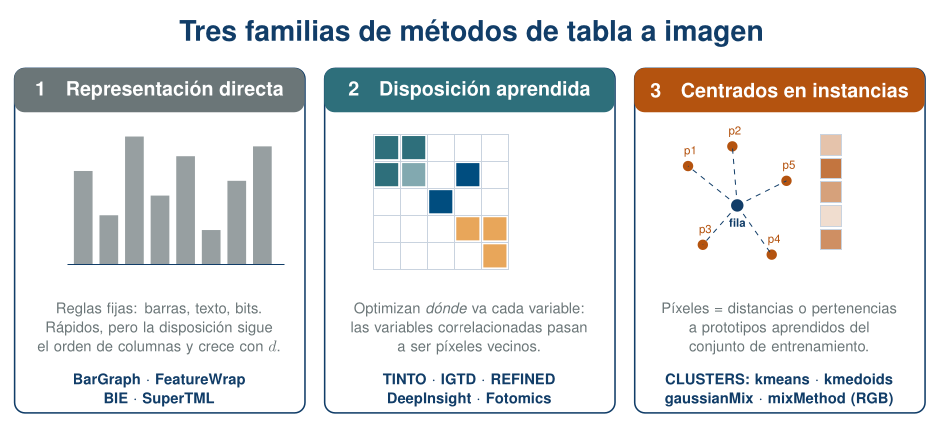

<p style="text-align:center; color:#555555;"><em><strong>Figura 3.</strong> Familias de representación tabular-a-imagen. No todos los codificadores tienen la misma interpretación de un píxel.</em></p>


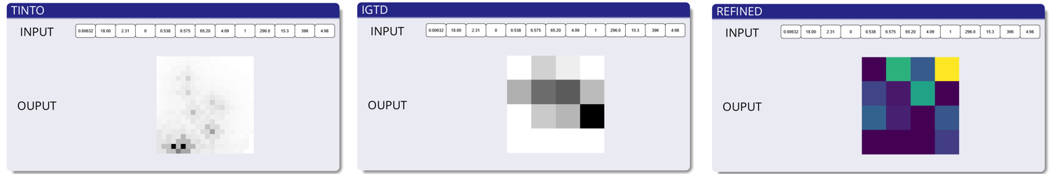

<p style="text-align:center; color:#555555;"><em><strong>Figura 4.</strong> Tres diseños visuales distintos para datos tabulares. La figura ilustra diferencias de organización, no resultados predictivos.</em></p>


<div class="alert alert-warning" style="background-color:#fff6e3; border-left:4px solid #cc8a25; padding:12px 15px; border-radius:5px; margin:12px 0;">
<strong>Dependencias y significado de los píxeles</strong><br>
REFINED es una ampliación opcional porque requiere MPI. CLUSTERS representa prototipos o componentes, no variables individuales. Para las demás opciones también hay que consultar sus parámetros y posibles restricciones antes de usar un método nuevo.
</div>


**Dimensionado óptimo de la cuadrícula para IGTD (`rejilla_igtd`)**

El método **IGTD** asigna una variable por píxel en una rejilla de tamaño $h \times w$. Esta función calcula las dimensiones óptimas para $n$ variables garantizando al menos $2$ filas y $2$ columnas: prioriza el **mínimo relleno** ($h \cdot w - n$) y desempata eligiendo la forma **más próxima a un cuadrado** ($|h - w|$ mínimo).


In [20]:
def rejilla_igtd(n):
    """Mínimo relleno con al menos 2 filas y 2 columnas; desempate por equilibrio."""
    if n < 4:
        return [2, max(2, math.ceil(n / 2))]
    opciones = [(h * math.ceil(n/h) - n, abs(h-math.ceil(n/h)), h, math.ceil(n/h))
                for h in range(2, math.isqrt(n) + 2)]
    _, _, filas, columnas = min(opciones)
    return [filas, columnas]

for n in (8, 12, 13, 30):
    f, c = rejilla_igtd(n)
    print(f"{n} variables → IGTD {f}×{c}, relleno = {f*c-n} píxeles")

8 variables → IGTD 2×4, relleno = 0 píxeles
12 variables → IGTD 3×4, relleno = 0 píxeles
13 variables → IGTD 2×7, relleno = 1 píxeles
30 variables → IGTD 5×6, relleno = 0 píxeles


**Registro docente de métodos e hiperparámetros (`REGISTRO`)**

Diccionario que vincula cada método con su submódulo, clase y configuración inicial. Las dimensiones espaciales de métodos como `IGTD`, `DeepInsight` o `Fotomics` se calculan automáticamente a partir del número de variables de entrada (`X_tr.shape[1]`).


In [25]:
# Selección docente: se pueden modificar los parámetros en estas líneas.
REGISTRO = {
    "TINTO": ("tinto", "TINTO", {"pixels": 20}),
    "IGTD": ("igtd", "IGTD", {"scale": rejilla_igtd(X_tr.shape[1]), "max_step": 100, "val_step": 20}),
    "DeepInsight": ("deepInsight", "DeepInsight", {"image_dim": math.ceil(math.sqrt(X_tr.shape[1])), "relocate": True}),
    "Fotomics": ("fotomics", "Fotomics", {"image_dim": math.ceil(math.sqrt(X_tr.shape[1])), "relocate": True}),
    "REFINED": ("refined", "REFINED", {"n_processors": 2, "hcIterations": 10}),
    "BIE": ("bie", "BIE", {}),
    # Opciones avanzadas: cambiar solo METODO; revisar dependencias del método.
    "BarGraph": ("barGraph", "BarGraph", {}),
    "DistanceMatrix": ("distanceMatrix", "DistanceMatrix", {}),
    "Combination": ("combination", "Combination", {}),
    "FeatureWrap": ("featureWrap", "FeatureWrap", {}),
    "SuperTML": ("supertml", "SuperTML", {}),
    "Clusters": ("clusters", "Clusters", {"algorithm": "kmeans", "n_clusters": 16}),
}


**Carga dinámica e instanciación con sus parámetros**

Comprueba requisitos específicos del entorno (como la disponibilidad de MPI para `REFINED`), importa únicamente el submódulo elegido mediante `import_module` y crea la instancia `transformador` pasando el tipo de problema (`problem=TAREA`) y los **parámetros** del método (`**opciones`).



In [26]:
modulo, clase, opciones = REGISTRO[METODO]

if METODO == "REFINED":
    import shutil
    if not (shutil.which("mpiexec") or shutil.which("mpirun")):
        raise RuntimeError("REFINED requiere MPI: selecciona otro método o configura MPI antes.")

Transformador = getattr(import_module("TINTOlib." + modulo), clase)
transformador = Transformador(problem=TAREA, **opciones)
print("Método:", METODO, "| Parámetros:", opciones)

Método: TINTO | Parámetros: {'pixels': 20}


<div class="alert alert-info" style="background-color:#eaf6fb; border-left:4px solid #00838A; padding:12px 15px; border-radius:5px; margin:12px 0;">
<strong>Cómo leer la primera salida</strong><br>
Se imprimen ejemplos de rejillas para diferentes cantidades de variables, cuántas posiciones quedarían vacías y los parámetros del método elegido. Para 8 variables se obtiene 2×4 sin relleno; con 13 variables, 2×7 tiene una posición vacía.
</div>


**Generación de imágenes en disco sin fuga de datos**

La función auxiliar `como_tabla` une predictores y objetivo en el formato que espera `TINTOlib`. Se crea una carpeta exclusiva para esta ejecución (`uuid4`) y se ejecuta **`fit_transform` solo con `TRAIN`** (aprendiendo la geometría espacial de las variables) y **`transform` con `VALIDATION`** (proyectando los nuevos datos sobre el mismo mapa aprendido).


In [27]:
def como_tabla(X, y):
    return X.reset_index(drop=True).assign(objetivo=np.asarray(y))

# Cada ejecución tiene una carpeta NUEVA; no se borran imágenes anteriores.
carpeta = Path("salidas_taller") / f"notebook_{DATASET}_{METODO}_{uuid4().hex[:6]}"
train_dir, val_dir = carpeta / "train", carpeta / "validation"

# convertir a imágenes y guardarlas en carpetas separadas para entrenamiento y validación
transformador.fit_transform(como_tabla(X_tr, y_tr), str(train_dir))
transformador.transform(como_tabla(X_va, y_va), str(val_dir))

**Función de recuperación y validación de rutas (`rutas_de_imagenes`)**

Define la función encargada de leer el archivo índice generado por `TINTOlib` (`regression.csv` o `classification.csv`), construir las rutas completas a partir de la columna `images` y comprobar mediante aserciones (`assert`) que el conteo coincide con el total de registros y que todos los archivos existen en disco.


In [29]:
def rutas_de_imagenes(directorio, total):
    meta = pd.read_csv(directorio / f"{TAREA}.csv")
    assert len(meta) == total and "images" in meta, "Revisar el CSV generado por TINTOlib"
    rutas = [directorio / nombre for nombre in meta["images"]]
    assert all(r.exists() for r in rutas), "Falta alguna imagen"
    return rutas

**Obtención de las listas de rutas para entrenamiento y validación**

Ejecuta `rutas_de_imagenes` sobre las carpetas `train/` y `validation/` para obtener las listas ordenadas `rutas_tr` y `rutas_va`, mostrando por pantalla el total de imágenes verificadas en cada partición.


In [30]:
rutas_tr = rutas_de_imagenes(train_dir, len(X_tr))
rutas_va = rutas_de_imagenes(val_dir, len(X_va))
print("Imágenes:", len(rutas_tr), "TRAIN y", len(rutas_va), "VALIDATION")

Imágenes: 353 TRAIN y 89 VALIDATION


<div class="alert alert-info" style="background-color:#eaf6fb; border-left:4px solid #00838A; padding:12px 15px; border-radius:5px; margin:12px 0;">
<strong>Qué significan los recuentos</strong><br>
El mensaje final indica cuántas imágenes se han creado por partición y dónde se guardan. Debe existir <strong>una imagen por fila</strong>. Se escriben en una carpeta nueva para evitar sobrescribir salidas anteriores.
</div>


---
<div style="text-align: right">
<font size=5>
<a href="#indice">Volver al índice</a>
</font>
</div>


<a id="section4" name="section4"></a>
# <font color="#004D7F" size=6>4. Imágenes generadas</font>


**Función de carga y conversión a tensores (`cargar_imagenes`)**

- Lee cada imagen en modo **RGB**, normaliza los píxeles de `[0, 255]` a `[0, 1]` (`float32`) y reordena sus ejes al formato **`(Canales, Alto, Ancho)`** exigido por PyTorch. 
- Finalmente, comprueba que todas las imágenes tengan idéntica resolución y las apila en un tensor 4D `(N, C, H, W)`.


In [31]:
def cargar_imagenes(rutas):
    imagenes = []
    formas = []
    for r in rutas:
        with Image.open(r) as im:
            rgb = np.asarray(im.convert("RGB"), dtype=np.float32) / 255.0
        imagenes.append(rgb.transpose(2, 0, 1))  # PyTorch: C, H, W
        formas.append(rgb.shape[:2])
    assert len(set(formas)) == 1, "Hay imágenes de distintos tamaños; revisa el transformador"
    return torch.tensor(np.stack(imagenes))

**Carga de particiones y lectura de dimensiones**

- Construye los tensores `img_tr` (`TRAIN`) e `img_va` (`VALIDATION`) y extrae automáticamente `canales`, `ALTO` y `ANCHO` para parametrizar las capas de entrada de la red neuronal.


In [32]:
img_tr, img_va = cargar_imagenes(rutas_tr), cargar_imagenes(rutas_va)
_, canales, ALTO, ANCHO = img_tr.shape
print(f"Imágenes: {ALTO} × {ANCHO} | canales={canales} | tensor={tuple(img_tr.shape)}")

Imágenes: 20 × 20 | canales=3 | tensor=(353, 3, 20, 20)


**Visualización de imágenes sintéticas y su valor objetivo**

- Representa las tres primeras observaciones de `TRAIN` permutando los ejes a `(H, W, C)` e indicando en el título el valor original de la variable objetivo (`tr[objetivo]`). 
- Se utiliza `interpolation="nearest"` (vecino más cercano) para ampliar los píxeles como bloques nítidos sin suavizado ni difuminado artificial, permitiendo observar la cuadrícula exacta que procesará la red. 
- Si se emplea **IGTD**, muestra además cuántas celdas han quedado como relleno sin variable asignada.


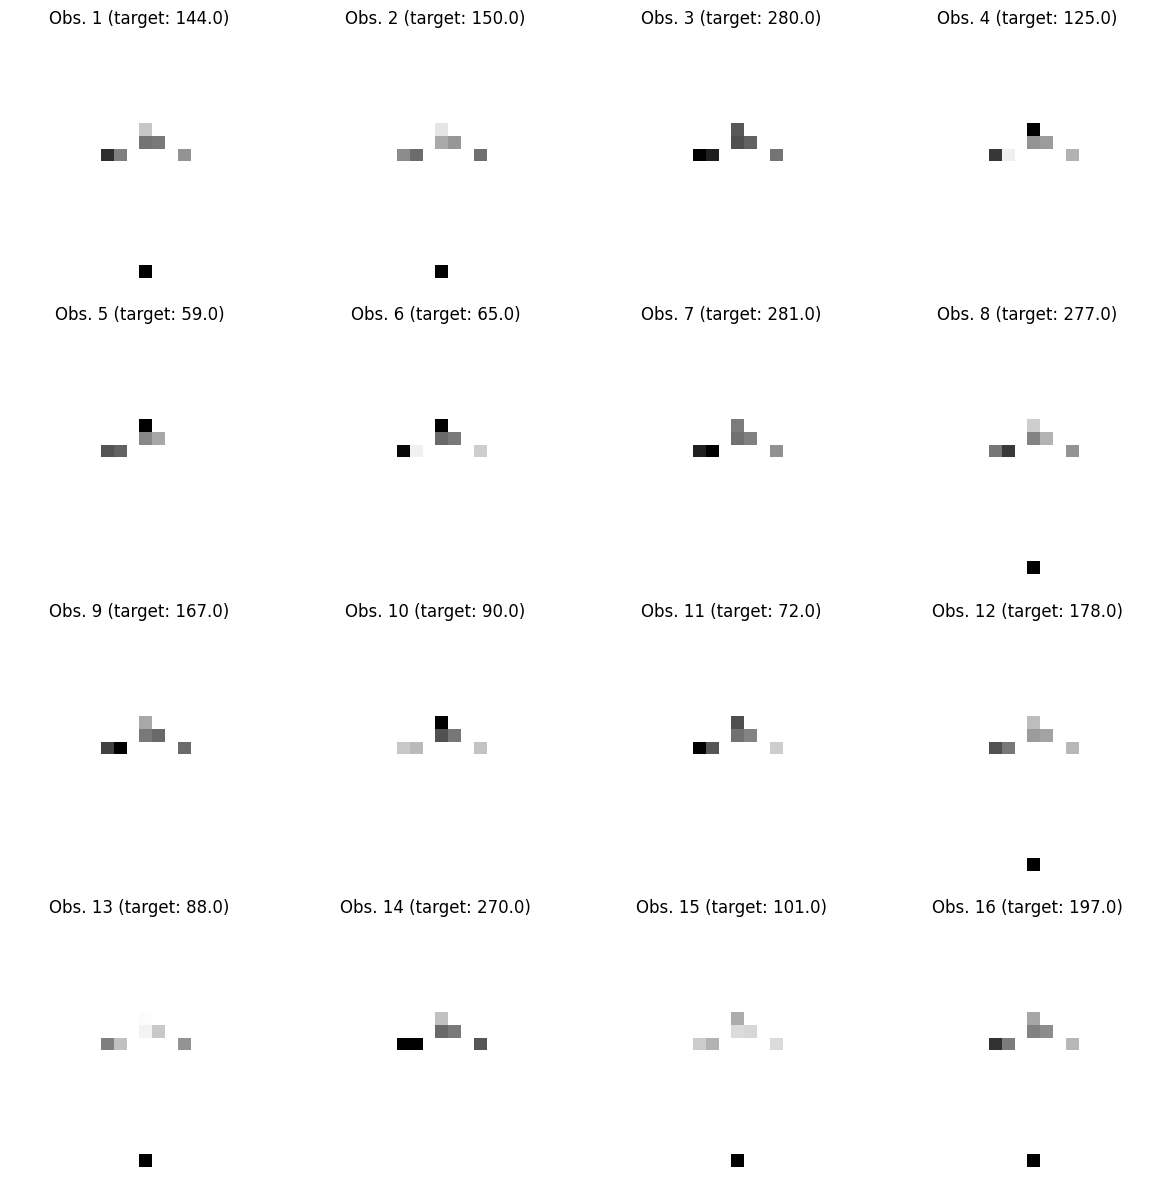

In [33]:
n_mostrar = min(16, len(img_tr))
if TAREA == "classification":
    clases_unicas = tr[objetivo].unique()
    por_clase = max(1, math.ceil(n_mostrar / len(clases_unicas)))
    indices = (
        tr.groupby(objetivo, group_keys=False)
        .head(por_clase)
        .sort_values(objetivo)
        .index[:n_mostrar]
        .tolist()
    )
else:
    indices = list(range(n_mostrar))

fig, axes = plt.subplots(4, 4, figsize=(12, 12))
for pos, ax in enumerate(axes.flat):
    if pos < len(indices):
        idx = indices[pos]
        ax.imshow(img_tr[idx].permute(1, 2, 0).numpy(), interpolation="nearest")
        valor_target = tr[objetivo].iloc[idx]
        etiqueta = f"{valor_target:.1f}" if TAREA == "regression" else f"{valor_target}"
        ax.set_title(f"Obs. {idx+1} ({objetivo}: {etiqueta})")
    ax.axis("off")
plt.tight_layout()
plt.show()

if METODO == "IGTD":
    filas, columnas = opciones["scale"]
    print("Celdas IGTD sin variable asignada:", filas * columnas - X_tr.shape[1])


<div style="background-color:#eaf6fb; border-left:4px solid #00838A; padding:10px 14px; border-radius:5px; margin:8px 0;">
<strong>LECTURA DE LA SALIDA · Una imagen TINTO más compacta</strong><br>
Con la configuración inicial <code>pixels=20</code>, la imagen tiene <b>20×20 = 400 celdas</b> para diez variables: como máximo diez celdas pueden representar variables de forma diferenciada y habrá <b>al menos 390 posiciones sin variable asignada</b>. 

8×8 reduciría mucho el espacio potencialmente vacío; <b>puede haber colisiones</b>. Observa la imagen y no presupongas una mejora predictiva.

<br><b>Nuevo ajuste:</b> Con <code>blur=True</code>, una celda sin variable asignada puede mostrar intensidad por la propagación de vecinos. En 20×20 el efecto puede ser marcado: observa las imágenes antes de interpretar el mapa de sensibilidad.
</div>

<div class="alert alert-info" style="background-color:#eaf6fb; border-left:4px solid #00838A; padding:12px 15px; border-radius:5px; margin:12px 0;">
<strong>Cómo interpretar las imágenes</strong><br>
Observa patrones y espacios no utilizados, diferencias entre observaciones y dimensiones impresas. Una imagen más grande o visualmente más llamativa no demuestra mayor capacidad predictiva. Si eliges IGTD, la consola indica también cuántas celdas no representan variables.

En este caso podemos ver en obs. 1, 2 y 3 que valores de target similares tiene un patron de imagen parecido
</div>


---
<div style="text-align: right">
<font size=5>
<a href="#indice">Volver al índice</a>
</font>
</div>


<a id="section5" name="section5"></a>
# <font color="#004D7F" size=6>5. Arquitectura CNN</font>


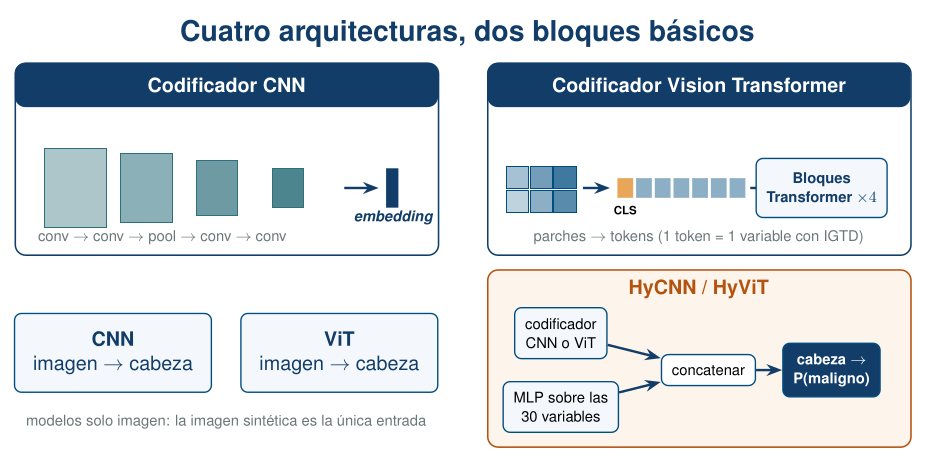

<p style="text-align:center; color:#555555;"><em><strong>Figura 5.</strong> Esquema de arquitecturas de visión e híbridas. En este notebook se implementa CNN; las demás sirven como comparación conceptual.</em></p>


El código siguiente contiene toda la arquitectura del ejemplo, sin componentes adicionales ni librerías de modelos preentrenados. Fíjate en **qué tensor entra, qué representación se extrae y qué tensor sale**.


**Extractor de características convolucional (`CNNSimple`)**

- Define dos capas convolucionales $3 \times 3$ con `padding=1` y activación `ReLU` ($3 \rightarrow 12 \rightarrow 24$ canales) que conservan la resolución original de la imagen sintética. 
- Finaliza con `AdaptiveAvgPool2d(1)` y `.flatten(1)` para resumir cada imagen en un vector de **$24$ características**, permitiendo procesar imágenes de cualquier dimensión ($H \times W$).


In [35]:
class CNNSimple(nn.Module):
    def __init__(self):
        super().__init__()
        self.capas = nn.Sequential(
            nn.Conv2d(3, 12, 3, padding=1), nn.ReLU(),
            nn.Conv2d(12, 24, 3, padding=1), nn.ReLU(),
            nn.AdaptiveAvgPool2d(1))

    def forward(self, x):
        return self.capas(x).flatten(1)  # [batch, 24]

**Ensamblaje del modelo con cabezal MLP y asignación de dispositivo (`Modelo`)**

- Conecta el extractor visual `CNNSimple` con un pequeño perceptrón multicapa (MLP) formado por una capa oculta de $8$ neuronas con activación `ReLU` y una neurona de salida lineal (`nn.Linear(8, 1)`) para regresión.
- Envía el modelo completo al hardware de cómputo seleccionado (`DISPOSITIVO`).
- El método `forward(img, tab)` acepta tanto la imagen como los datos tabulares para mantener la misma interfaz que los modelos híbridos posteriores, aunque en este notebook emplea únicamente `img`.


In [36]:
class Modelo(nn.Module):
    def __init__(self):
        super().__init__()
        self.visual = CNNSimple()
        self.salida = nn.Sequential(
            nn.Linear(24, 8),
            nn.ReLU(),
            nn.Linear(8, 1)
        )

    def forward(self, img, tab):
        return self.salida(self.visual(img))

modelo = Modelo().to(DISPOSITIVO)

**Prueba de dimensiones y conteo de parámetros**

- Realiza una pasada hacia adelante de comprobación con dos muestras dentro de `torch.no_grad()` (sin calcular gradientes) para verificar que la forma de salida sea `[2, 1]` e imprime el número total de parámetros entrenables de la red.


In [38]:
with torch.no_grad():
    salida = modelo(img_tr[:2].to(DISPOSITIVO), tab_tr[:2].to(DISPOSITIVO))

print("Entrada imágenes:", tuple(img_tr[:2].shape), "→ salida:", tuple(salida.shape))
print("Parámetros:", sum(p.numel() for p in modelo.parameters() if p.requires_grad))

Entrada imágenes: (2, 3, 20, 20) → salida: (2, 1)
Parámetros: 3161


<div class="alert alert-info" style="background-color:#eaf6fb; border-left:4px solid #00838A; padding:12px 15px; border-radius:5px; margin:12px 0;">
<strong>Qué indica la salida del modelo</strong><br>
Se muestran la forma de un pequeño lote de imágenes, la forma de la salida y el número de parámetros entrenables. Para regresión la salida tiene forma <code>(2, 1)</code>: una predicción continua por observación. El número de parámetros no es una medida de rendimiento.
</div>


---
<div style="text-align: right">
<font size=5>
<a href="#indice">Volver al índice</a>
</font>
</div>


<a id="section6" name="section6"></a>
# <font color="#004D7F" size=6>6. Entrenamiento y resultados</font>


PyTorch repite un ciclo sencillo: **predicción → cálculo de pérdida → gradientes → actualización de pesos**. A continuación calcula la pérdida sobre VALIDATION, que no se utiliza para actualizar parámetros.

La gráfica muestra cómo evoluciona esa pérdida durante las pocas épocas de demostración. Una curva que baja es compatible con aprendizaje, pero no prueba capacidad de generalización ni permite concluir qué transformación es la mejor.


**Configuración de lotes (`DataLoader`), función de pérdida y optimizador**

- Empaqueta los tensores de imagen, datos tabulares y objetivo en objetos `TensorDataset` y crea los `DataLoader` con lotes de $32$ observaciones, barajando los datos en entrenamiento (`shuffle=True`) para evitar sesgos por orden.
- Selecciona la función de pérdida adecuada según la tarea (`CrossEntropyLoss` para clasificación o `MSELoss` para regresión).
- Inicializa el optimizador `Adam` con tasa de aprendizaje `lr=1e-3` sobre los parámetros entrenables del modelo.


In [39]:
train_loader = DataLoader(TensorDataset(img_tr, tab_tr, y_tr_tensor),
                          batch_size=32, shuffle=True)
val_loader = DataLoader(TensorDataset(img_va, tab_va, y_va_tensor),
                        batch_size=32)
criterio = nn.CrossEntropyLoss() if TAREA=="classification" else nn.MSELoss()
optimizador = torch.optim.Adam(modelo.parameters(),lr=1e-3)

**Bucle de entrenamiento, validación y curva de pérdida**

- En cada época, activa `modelo.train()` y recorre los mini-lotes de entrenamiento ejecutando la limpieza de gradientes (`zero_grad`), la predicción (*forward*), el cálculo del *loss* (ajustando la forma de `y` a `[batch, 1]` en regresión), la retropropagación (`backward`) y la actualización de pesos (`step`).
- Tras cada época, activa `modelo.eval()` y `torch.no_grad()` para evaluar el *loss* medio (MSE en regresión o entropía cruzada en clasificación) sobre todo el conjunto de `VALIDATION` sin almacenar gradientes.
- Registra el historial de validación y grafica la evolución del *loss* a lo largo de las épocas para comprobar si el modelo converge correctamente.


Época 1: pérdida VALIDATION=0.8668
Época 2: pérdida VALIDATION=0.8673
Época 3: pérdida VALIDATION=0.8675
Época 4: pérdida VALIDATION=0.8678
Época 5: pérdida VALIDATION=0.8679


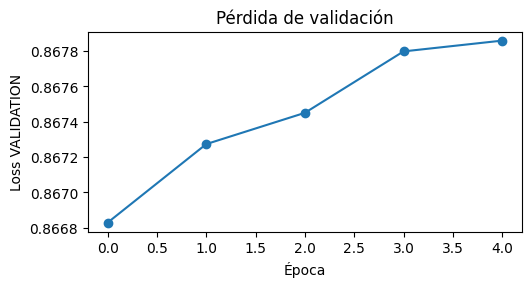

In [40]:
historial = []
for epoca in range(EPOCAS):
    modelo.train()
    for img, tab, y in train_loader:
        optimizador.zero_grad()
        pred = modelo(img.to(DISPOSITIVO), tab.to(DISPOSITIVO))
        loss = criterio(pred, y.to(DISPOSITIVO).long() if TAREA=="classification"
                        else y.to(DISPOSITIVO).view(-1,1))
        loss.backward()
        optimizador.step()
    modelo.eval()
    with torch.no_grad():
        val_loss = np.mean([criterio(modelo(a.to(DISPOSITIVO),b.to(DISPOSITIVO)),
                          y.to(DISPOSITIVO).long() if TAREA=="classification"
                          else y.to(DISPOSITIVO).view(-1,1)).item()
                          for a,b,y in val_loader])
    historial.append(val_loss)
    print(f"Época {epoca+1}: pérdida VALIDATION={val_loss:.4f}")
plt.figure(figsize=(5.6,2.6))
plt.plot(historial,marker="o");plt.xlabel("Época");plt.ylabel("Loss VALIDATION")
plt.title("Pérdida de validación");plt.show()

<div style="background-color:#eaf6fb; border-left:4px solid #00838A; padding:10px 14px; border-radius:5px; margin:8px 0;">
<strong>LECTURA DE LA SALIDA · Cómo leer la pérdida de validación</strong><br>
Cada punto representa la pérdida calculada sobre <b>VALIDATION</b> tras una época de entrenamiento. Una curva descendente sugiere mejor ajuste de validación; si deja de bajar o fluctúa, coméntalo sin concluir sobreajuste con solo cinco épocas. <b>No es una gráfica de pérdida de TRAIN.</b>
</div>

<div class="alert alert-info" style="background-color:#eaf6fb; border-left:4px solid #00838A; padding:12px 15px; border-radius:5px; margin:12px 0;">
<strong>Cómo leer la gráfica de entrenamiento</strong><br>
El eje horizontal muestra las épocas; el vertical, la pérdida calculada en VALIDATION. Valores menores suelen ser preferibles dentro de la misma tarea y escala, pero una curva corta o irregular no basta para extraer conclusiones.
</div>


**Evaluación final y cálculo de métricas en `VALIDATION`**

- Activa `modelo.eval()` y `torch.no_grad()` para generar las predicciones sobre todo el conjunto de validación y las convierte de vuelta a un array de NumPy en CPU.
- En **regresión**, aplica `escala_y.inverse_transform()` tanto a las predicciones como a los valores reales para revertir la estandarización y calcular **MAE**, **RMSE** y **$R^2$** en las unidades originales del problema.
- En **clasificación**, obtiene la clase ganadora mediante `.argmax(axis=1)` y evalúa el rendimiento con **Accuracy** y **F1 macro**.
- Muestra el aviso recordando que las métricas corresponden únicamente a `VALIDATION` en un entorno de demostración y no a un conjunto `TEST` final.


In [41]:
modelo.eval()
with torch.no_grad():
    pred = modelo(img_va.to(DISPOSITIVO), tab_va.to(DISPOSITIVO)).cpu().numpy()
if TAREA == "regression":
    estimacion = escala_y.inverse_transform(pred.reshape(-1,1)).ravel()
    real = escala_y.inverse_transform(y_va.reshape(-1,1)).ravel()
    print("MAE:",round(mean_absolute_error(real,estimacion),3),
          "| RMSE:",round(np.sqrt(mean_squared_error(real,estimacion)),3),
          "| R²:",round(r2_score(real,estimacion),3))
else:
    clases_pred = pred.argmax(axis=1)
    print("Accuracy:",round(accuracy_score(y_va,clases_pred),3),
          "| F1 macro:",round(f1_score(y_va,clases_pred,average="macro"),3))
print("Solo VALIDATION: no son resultados de un benchmark.")

MAE: 63.421 | RMSE: 72.848 | R²: -0.002
Solo VALIDATION: no son resultados de un benchmark.


<div style="background-color:#eaf6fb; border-left:4px solid #00838A; padding:10px 14px; border-radius:5px; margin:8px 0;">
<strong>LECTURA DE LA SALIDA · MAE, RMSE y R²</strong><br>
MAE y RMSE muestran errores en las unidades originales del objetivo. Un <b>R² próximo a cero</b> significa poca mejora frente al predictor constante de referencia; un R² negativo indica que resulta peor. Revisa los números obtenidos <b>después de ejecutar</b>: cambiar de 8×8 a 4×4 no garantiza mejorar el rendimiento.
</div>

<div class="alert alert-success" style="background-color:#e9f7f0; border-left:4px solid #2e7d61; padding:12px 15px; border-radius:5px; margin:12px 0;">
<strong>Cómo interpretar las métricas</strong><br>
- <strong>MAE:</strong> error absoluto medio, en unidades del objetivo original (menor es mejor).<br>- <strong>RMSE:</strong> penaliza más los errores grandes; también se expresa en unidades del objetivo (menor es mejor).<br>- <strong>R²:</strong> compara el ajuste frente a predecir siempre la media; puede ser negativo (más alto es mejor).
</div>


<div class="alert alert-warning" style="background-color:#fff7e6; border-left:4px solid #E8A65A; padding:12px 15px; border-radius:5px; margin:12px 0;">
<strong>Lectura de esta ejecución</strong><br>
La pérdida de <b>VALIDATION</b> baja ligeramente al principio y después se estabiliza. En esta ejecución se obtiene <b>MAE ≈ 63.95</b>, <b>RMSE ≈ 73.18</b> y <b>R² ≈ -0.01</b>. Esto indica que, con solo cinco épocas y esta configuración compacta de <code>TINTO</code> (<code>20×20</code>, <code>blur=True</code>), la CNN <b>apenas mejora</b> frente a una referencia muy simple. Es un buen ejemplo docente de que convertir una tabla en imagen <b>no garantiza</b> mejor rendimiento: la representación y la arquitectura deben ajustarse al problema.</div>

<div class="alert alert-info" style="background-color:#eaf6fb; border-left:4px solid #00838A; padding:12px 15px; border-radius:5px; margin:12px 0;">
<strong>Qué conviene comentar en clase</strong><br>
El desenfoque de TINTO reparte intensidad a vecinos y hace la imagen algo más suave, pero <b>no añade variables nuevas</b>. Puede cambiar el patrón espacial que recibe la CNN, aunque en esta ejecución no ha sido suficiente para lograr una mejora clara en regresión.</div>

---
<div style="text-align: right">
<font size=5>
<a href="#indice">Volver al índice</a>
</font>
</div>


<a id="section7" name="section7"></a>
# <font color="#004D7F" size=6>7. Explicabilidad visual (opcional)</font>


**Cálculo de gradientes respecto a la entrada (explicabilidad local)**

- Activa `modelo.eval()`, clona la primera observación de `VALIDATION` y habilita `requires_grad_(True)` para que PyTorch registre las derivadas respecto a los píxeles de entrada y las variables tabulares.
- Ejecuta una predicción y selecciona el escalar objetivo (`logit` máximo en clasificación o valor continuo en regresión) sobre el que lanzar `valor.backward()`.
- Obtiene así los gradientes `imagen.grad` (y `tabla.grad` si existe rama tabular), que miden cuánto influye cada entrada en la predicción de esa observación concreta.


In [56]:
# OPCIONAL · Una observación de VALIDATION, sin instalar librerías nuevas.
modelo.eval()
imagen = img_va[:1].to(DISPOSITIVO).detach().clone().requires_grad_(True)
tabla = tab_va[:1].to(DISPOSITIVO).detach().clone().requires_grad_(True)
modelo.zero_grad()
prediccion = modelo(imagen, tabla)
valor = prediccion[0].max() if TAREA == "classification" else prediccion[0, 0]
valor.backward()

**Visualización del mapa de saliencia y superposición**

- Calcula la sensibilidad espacial de cada píxel tomando la magnitud media de sus gradientes en los tres canales RGB (`abs().mean(dim=1)`).
- Muestra en paralelo la imagen sintética original, el mapa de calor de sensibilidad local (`inferno`) y la superposición de ambos con transparencia (`alpha=0.5`).
- Si la arquitectura emplea también una rama tabular (`grad_tab is not None`), añade automáticamente un cuarto panel con las $5$ variables de mayor impacto local para esa muestra.


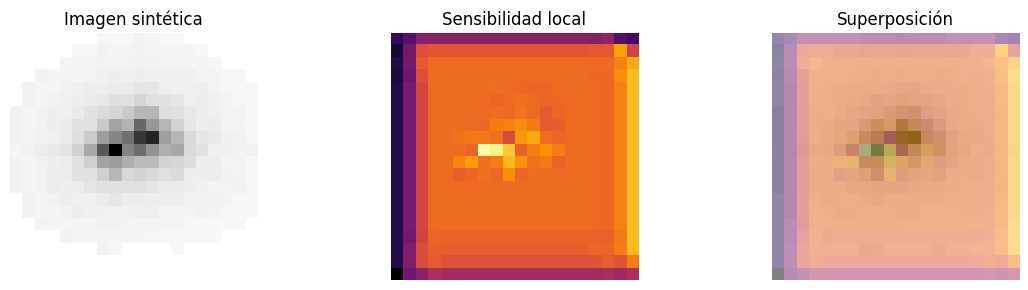

In [57]:
mapa = imagen.grad.detach().abs().mean(dim=1)[0].cpu().numpy()
original = img_va[0].permute(1, 2, 0).numpy()
grad_tab = tabla.grad  # Solo existe si la red utiliza la rama MLP.
fig, ejes = plt.subplots(1, 4 if grad_tab is not None else 3, figsize=(12, 3))
ejes[0].imshow(original); ejes[0].set_title("Imagen sintética")
ejes[1].imshow(mapa, cmap="inferno", interpolation="nearest")
ejes[1].set_title("Sensibilidad local")
ejes[2].imshow(original)
ejes[2].imshow(mapa, cmap="inferno", alpha=0.5, interpolation="nearest")
ejes[2].set_title("Superposición")
for eje in ejes[:3]: eje.axis("off")
if grad_tab is not None:
    importancia = grad_tab[0].abs().detach().cpu().numpy()
    mejores = np.argsort(importancia)[-min(5, len(importancia)):]
    nombres = [str(X_tr.columns[i])[:20] for i in mejores]
    ejes[3].barh(nombres, importancia[mejores], color="#2E6F7B")
    ejes[3].set_title("Rama tabular (local)")
    ejes[3].tick_params(labelsize=8)
plt.tight_layout(); plt.show()

<div style="background-color:#eaf6fb; border-left:4px solid #00838A; padding:10px 14px; border-radius:5px; margin:8px 0;">
<strong>LECTURA DE LA SALIDA · El mapa de sensibilidad</strong><br>
Las zonas resaltadas indican dónde cambia localmente la predicción al modificar ligeramente la intensidad de la imagen. También pueden aparecer gradientes en posiciones sin variable asignada por el campo receptivo convolucional. <b>No equivalen a un ranking causal de variables ni demuestran fidelidad explicativa.</b>
</div>

<div class="alert alert-warning" style="background-color:#fff6e3; border-left:4px solid #cc8a25; padding:12px 15px; border-radius:5px; margin:12px 0;">
<strong>Cómo interpretar esta explicación</strong><br>
Una región brillante indica <b>sensibilidad local del modelo</b>, no una causa del resultado. La barra tabular, cuando aparece, utiliza variables estandarizadas y no debe compararse directamente con los colores de la imagen. Para relacionar un píxel con una variable original hace falta el mapeo específico del transformador y comprobar su fidelidad; este ejemplo no implementa esa validación.
</div>


---
<div style="text-align: right">
<font size=5>
<a href="#indice">Volver al índice</a>
</font>
</div>


<a id="section8" name="section8"></a>
# <font color="#004D7F" size=6>8. Conclusiones</font>


1. **El método de transformación es una decisión importante:** con TINTO, una observación de Diabetes se convierte en una imagen cuya estructura debe interpretarse.
2. **No hay fuga de información:** la transformación y los escaladores se ajustan solo en TRAIN, y VALIDATION reutiliza ese estado.
3. **La arquitectura se entiende por su recorrido de tensores:** imagen (y tabla, si hay MLP), extractor, fusión si corresponde y predicción.
4. **Las salidas muestran lo que ha ocurrido en este ensayo:** tamaños, imágenes, pérdida y métricas de validación, no una conclusión científica general.
5. **Explicabilidad como primer contacto:** los mapas locales son ilustrativos; no prueban causalidad ni fidelidad.

La CNN utiliza la vecindad de píxeles de la imagen para extraer patrones; no necesita que la imagen sea cuadrada.


---
<div style="text-align: right">
<font size=5>
<a href="#indice">Volver al índice</a>
</font>
</div>


<a id="section9" name="section9"></a>
# <font color="#004D7F" size=6>9. Ejercicios</font>


<div class="alert alert-info" style="background-color:#eaf6fb; border-left:4px solid #00838A; padding:12px 15px; border-radius:5px; margin:12px 0;">
<strong>Trabajo propuesto · 10 minutos.</strong><br>
Realiza uno o dos cambios pequeños y describe las imágenes y las salidas, no solo el valor de la métrica.
</div>

1. **Compara representaciones.** Cambia `METODO` por otro de la tabla y vuelve a ejecutar desde la configuración. ¿Qué cambia en la forma y apariencia de las imágenes?
2. **Interpreta la salida.** Explica con tus palabras qué representan el tensor de entrada, la predicción y MAE/RMSE/R².
3. **Compara tamaños TINTO.** En el registro de métodos cambia `"pixels": 4` por `"pixels": 8`, vuelve a ejecutar y compara la cantidad de posiciones vacías. ¿Mejora necesariamente el R²?
4. **Desenfoque (opcional).** Cambia `"blur": True` por `False`, vuelve a generar imágenes y observa las diferencias visuales. ¿Cambian también las métricas en VALIDATION? No presupongas una mejora.
5. **Opcional, explicabilidad.** Observa el mapa de sensibilidad local. ¿Qué muestra realmente? ¿Por qué no demuestra causalidad?

<b>Continuación:</b> el notebook **06 · TINTOlib hands-on v3 (ES)** amplía el estudio con más métodos de transformación, evaluación rigurosa y técnicas XAI de mayor profundidad.


---
<div style="text-align: right">
<font size=5>
<a href="#indice">Volver al índice</a>
</font>
</div>


<a id="section10" name="section10"></a>
# <font color="#004D7F" size=6>10. Referencias</font>


- **TINTOlib**. [Repositorio de Python](https://github.com/oeg-upm/TINTOlib) · [Documentación de la biblioteca](https://tintolib.readthedocs.io/en/latest/).
- **TINTO**. Castillo-Cara et al. (2023). *TINTO: Converting Tidy Data into Image for Classification with 2-D Convolutional Neural Networks*. [SoftwareX](https://doi.org/10.1016/j.softx.2023.101391).
- **TINTOlib**. Liu et al. (2025). *TINTOlib: A Python library for transforming tabular data into synthetic images for deep neural networks*. [SoftwareX](https://doi.org/10.1016/j.softx.2025.102444).
- **Benchmark de codificadores**. Liu et al. (2026). *A comprehensive benchmark of spatial encoding methods for tabular data with deep neural networks*. [Information Fusion](https://doi.org/10.1016/j.inffus.2025.104088).
- **PyTorch**. [nn.Module](https://pytorch.org/docs/stable/generated/torch.nn.Module.html) · [TransformerEncoderLayer](https://pytorch.org/docs/stable/generated/torch.nn.TransformerEncoderLayer.html).
- **Recursos adicionales**. 
    - [TINTOlib Crash Course](https://github.com/oeg-upm/TINTOlib-Crash_Course) 
    - [Blog de tutoriales](https://www.manuelcastillo.eu/blog/) 

---
<div style="text-align: right">
<font size=5>
<a href="#indice">Volver al índice</a>
</font>
</div>
